In [1]:
# set up libraries
import numpy as np
import matplotlib.pyplot as plt
from astroquery.simbad import Simbad
import astropy.coordinates as coord
import pandas
import scipy
# set up custom query and define which columns we want
customSimbad = Simbad()
customSimbad.add_votable_fields('ra', 'dec', 'mesdistance', 'otype','rvz_radvel', 'rvz_redshift')
#customSimbad.remove_votable_fields('coordinates')
# set RA, Dec and search radius
my_ra = 227.773
my_dec = 5.744
# use 0.25 degrees as an example
my_radius = '0d29m35s'
# run query
result_table = customSimbad.query_region(coord.SkyCoord(my_ra,my_dec, unit='deg'),radius=my_radius)
# convert output to pandas data frame
df = result_table.to_pandas()

print("The columns in the data frame are:\n",df.columns.values,"\n")
gal_df=df[df['otype']=='G']
print('Selected',len(gal_df),'galaxies')
print(gal_df['rvz_radvel'])

The columns in the data frame are:
 ['main_id' 'ra' 'dec' 'coo_err_maj' 'coo_err_min' 'coo_err_angle'
 'coo_wavelength' 'coo_bibcode' 'rvz_radvel' 'otype' 'rvz_redshift'
 'mesdistance.bibcode' 'mesdistance.dist' 'mesdistance.dist_prec'
 'mesdistance.mespos' 'mesdistance.method' 'mesdistance.minus_err'
 'mesdistance.minus_err_prec' 'mesdistance.plus_err'
 'mesdistance.plus_err_prec' 'mesdistance.qual' 'mesdistance.unit'] 

Selected 3368 galaxies
0       119054.559937
2        11409.332744
3        70151.797550
4        61266.748718
6        90654.844628
            ...      
3644     27333.881843
3646     27521.025530
3647     28024.805859
3648     28051.862158
3649     28230.360399
Name: rvz_radvel, Length: 3368, dtype: float64


In [2]:

options = Simbad.list_votable_fields()
# to print only the available bundles of columns
options[options["type"] == "bundle of basic columns"][["name", "description"]]
print(options[options["type"] == "velocity"])

name description type
---- ----------- ----


In [3]:
Simbad.list_votable_fields()[70:80]


name,description,type
object,object,object
rvz_bibcode,Radial velocity / redshift reference,column of basic
rvz_err,Radial velocity / redshift error,column of basic
rvz_err_prec,Radial velocity / redshift error precision,column of basic
rvz_nature,velocity / redshift nature,column of basic
rvz_qual,Radial velocity / redshift quality,column of basic
rvz_radvel,Radial Velocity,column of basic
rvz_radvel_prec,Radial velocity precision,column of basic
rvz_redshift,redshift,column of basic
rvz_redshift_prec,redshift precision,column of basic


Text(0, 0.5, 'Number of galaxies')

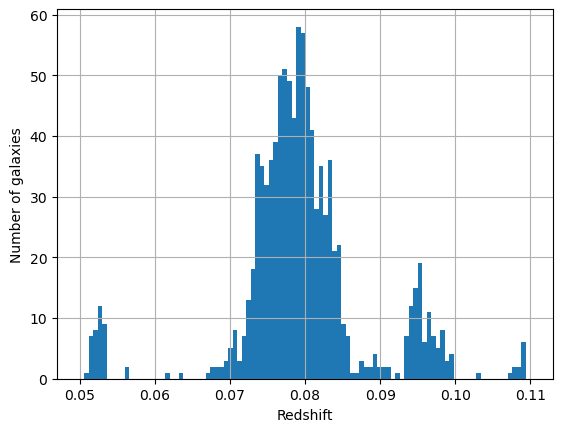

In [4]:
gal_df['rvz_redshift'].hist(bins=100, range=(0.05,0.11))
plt.xlabel('Redshift')
plt.ylabel('Number of galaxies')

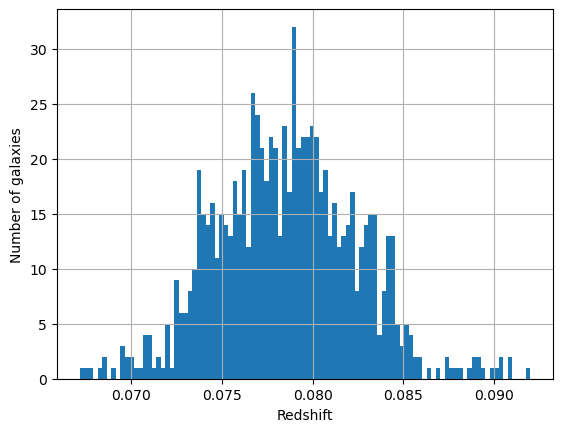

<function matplotlib.pyplot.show(close=None, block=None)>

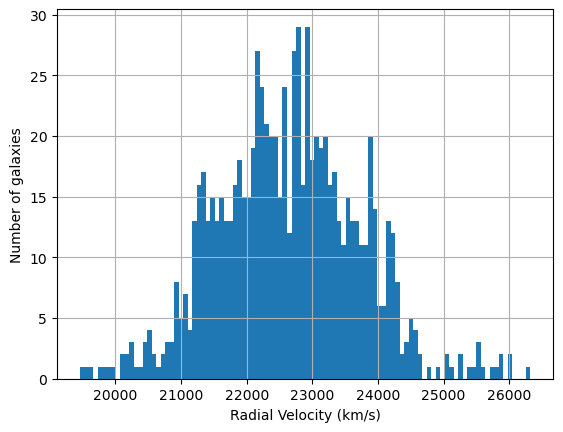

In [5]:
galaxy_cluster = gal_df[(gal_df['rvz_redshift'] <0.093 )& (gal_df['rvz_redshift'] >0.065)]
galaxy_cluster['rvz_redshift'].hist(bins=100)
plt.xlabel('Redshift')
plt.ylabel('Number of galaxies')
plt.show()
galaxy_cluster['rvz_radvel'].hist(bins=100)
plt.xlabel('Radial Velocity (km/s)')
plt.ylabel('Number of galaxies')
plt.show

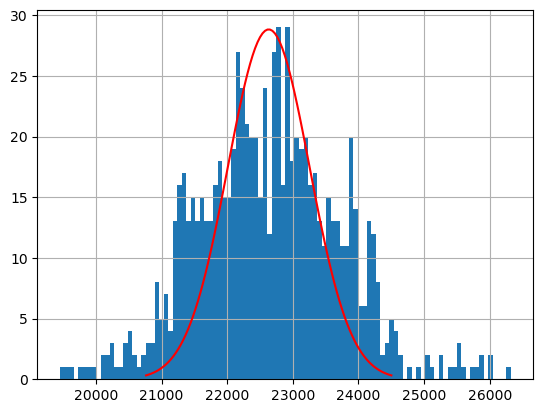

In [6]:
standardised_plot = galaxy_cluster['rvz_radvel']
standardised_plot.hist(bins=100)
import scipy.stats as stats
mean =galaxy_cluster['rvz_radvel'].mean()
standarddev= galaxy_cluster['rvz_radvel'].std()/np.sqrt(3)
x = np.linspace(mean - 3*standarddev, mean + 3*standarddev, 100)
plt.plot(x, stats.norm.pdf(x, mean, standarddev)*45000,'r')
plt.show()

In [7]:
import astropy.constants as cons
import scipy.constants as math_cons
from astropy.cosmology import WMAP9 as cosmo
from astropy import units as u
import astropy.cosmology.units as cu

redshift = 0.0766
rho_200 = 200*cosmo.critical_density(redshift).to(u.kg/u.m**3)
standarddev_SI = standarddev*(u.km/u.s)
M_200 = np.sqrt(((27)/(cons.G**3))*(standarddev_SI**6)*((3)/(4*math_cons.pi*rho_200)))
M_200 = M_200.to(u.solMass)
print('M_200 is',M_200)
R_200 = (3*M_200/(4*math_cons.pi*rho_200))**(1/3)
R_200 = R_200.to(u.kpc)/cosmo.kpc_proper_per_arcmin(redshift)

print('R_200 is',R_200)


M_200 is 406771017356750.56 solMass
R_200 is 17.084366332878957 arcmin


In [8]:
print(M_200/10**15,'x10^15')

0.4067710173567506 solMass x10^15


In [9]:
#eckert M 200 data
eckert_M_HSE = 12.25*10**14*(u.solMass)
eckert_M_HSE_uncertainty = 0.49*10**14*(u.solMass)
eckert_f_gas = 0.152
eckert_f_gas_uncertainty = 0.006

M_gas_eckert = eckert_f_gas * eckert_M_HSE
M_gas_eckert_uncertainty = np.sqrt((eckert_M_HSE**2)*(eckert_f_gas_uncertainty**2)+(eckert_f_gas**2)*(eckert_M_HSE_uncertainty**2))

#our M 200 data
f_gas = M_gas_eckert / M_200

print('Values for M 200')
print('Eckert et al:',eckert_M_HSE/(10**15),'x10^15','Our calculations:',M_200/(10**15),'x10^15')

print('Values for gas fraction')
print('Eckert et al:',eckert_f_gas,'Our calculations:',f_gas)

#finding omega M
f_star = 0.015
f_star_uncertainty=0.005
f_b = f_star + f_gas

omega_b = 0.03
omega_M = omega_b/f_b
print('Matter density is:',omega_M)

Values for M 200
Eckert et al: 1.225 solMass x10^15 Our calculations: 0.4067710173567506 solMass x10^15
Values for gas fraction
Eckert et al: 0.152 Our calculations: 0.4577513934251047
Matter density is: 0.06345830053011303


In [10]:
#loop:

run number 1
The columns in the data frame are:
 ['main_id' 'ra' 'dec' 'coo_err_maj' 'coo_err_min' 'coo_err_angle'
 'coo_wavelength' 'coo_bibcode' 'rvz_radvel' 'otype' 'rvz_redshift'
 'mesdistance.bibcode' 'mesdistance.dist' 'mesdistance.dist_prec'
 'mesdistance.mespos' 'mesdistance.method' 'mesdistance.minus_err'
 'mesdistance.minus_err_prec' 'mesdistance.plus_err'
 'mesdistance.plus_err_prec' 'mesdistance.qual' 'mesdistance.unit'] 

Selected 1767 galaxies
0       119054.559937
1        11409.332744
2        61266.748718
4        90818.230110
5        90714.638059
            ...      
1955     27184.609507
1956     27333.881843
1957     28024.805859
1958     28051.862158
1959     28230.360399
Name: rvz_radvel, Length: 1767, dtype: float64


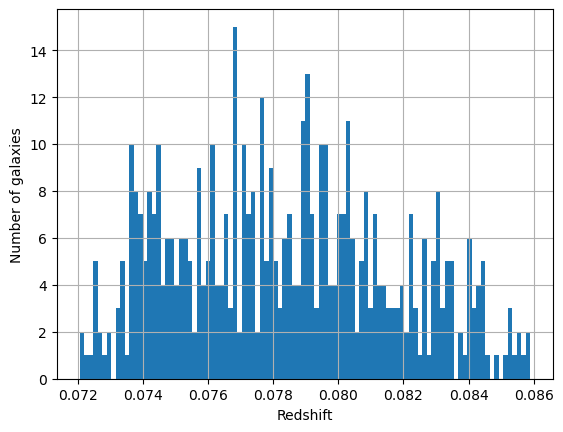

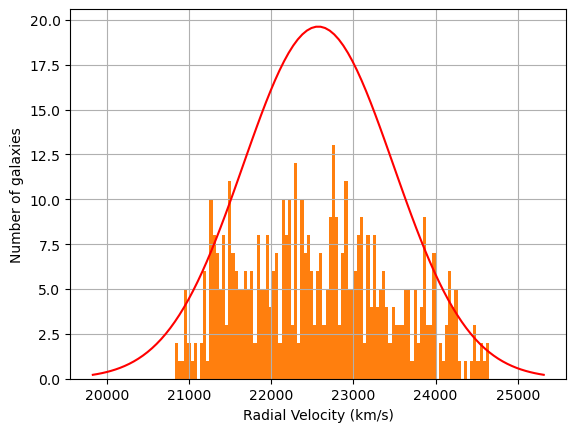

M_200 is 2.5636029671403755e+36 km3 kg / m3
1200.0 arcsec 1505.7345308738734 arcsec
R_200 is 1505.7345308738734 arcsec
condition -152.8672654369368 arcsec
self consistent False
run number 2
The columns in the data frame are:
 ['main_id' 'ra' 'dec' 'coo_err_maj' 'coo_err_min' 'coo_err_angle'
 'coo_wavelength' 'coo_bibcode' 'rvz_radvel' 'otype' 'rvz_redshift'
 'mesdistance.bibcode' 'mesdistance.dist' 'mesdistance.dist_prec'
 'mesdistance.mespos' 'mesdistance.method' 'mesdistance.minus_err'
 'mesdistance.minus_err_prec' 'mesdistance.plus_err'
 'mesdistance.plus_err_prec' 'mesdistance.qual' 'mesdistance.unit'] 

Selected 2154 galaxies
0       119054.559937
1        11409.332744
2        61266.748718
4        90818.230110
5        90714.638059
            ...      
2370     27184.609507
2371     27333.881843
2373     28024.805859
2374     28051.862158
2375     28230.360399
Name: rvz_radvel, Length: 2154, dtype: float64


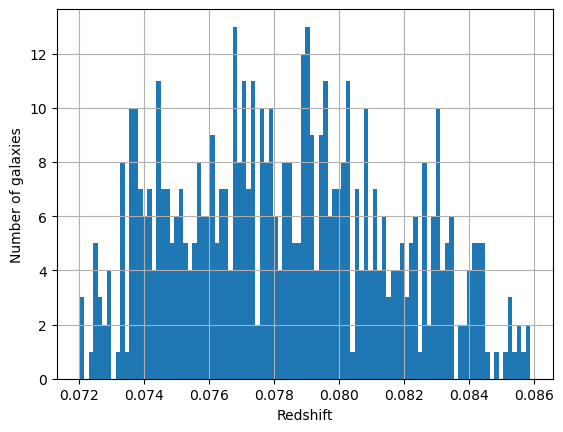

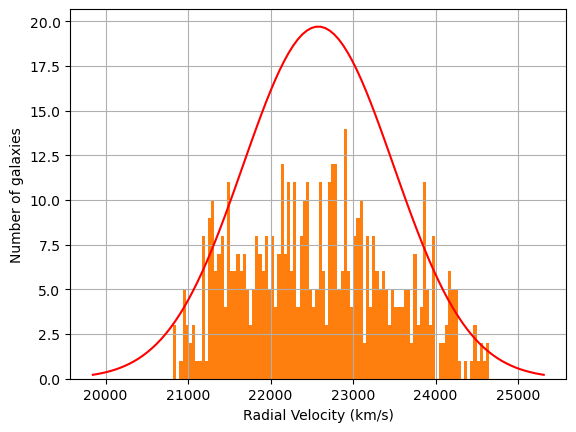

M_200 is 2.5321745583912823e+36 km3 kg / m3
1352.8672654369366 arcsec 1499.5560452082589 arcsec
R_200 is 1499.5560452082589 arcsec
condition -73.34438988566103 arcsec
self consistent False
run number 3
The columns in the data frame are:
 ['main_id' 'ra' 'dec' 'coo_err_maj' 'coo_err_min' 'coo_err_angle'
 'coo_wavelength' 'coo_bibcode' 'rvz_radvel' 'otype' 'rvz_redshift'
 'mesdistance.bibcode' 'mesdistance.dist' 'mesdistance.dist_prec'
 'mesdistance.mespos' 'mesdistance.method' 'mesdistance.minus_err'
 'mesdistance.minus_err_prec' 'mesdistance.plus_err'
 'mesdistance.plus_err_prec' 'mesdistance.qual' 'mesdistance.unit'] 

Selected 2357 galaxies
0       119054.559937
2        11409.332744
3        61266.748718
5        23117.941625
6        90818.230110
            ...      
2584     27184.609507
2585     27333.881843
2587     28024.805859
2588     28051.862158
2589     28230.360399
Name: rvz_radvel, Length: 2357, dtype: float64


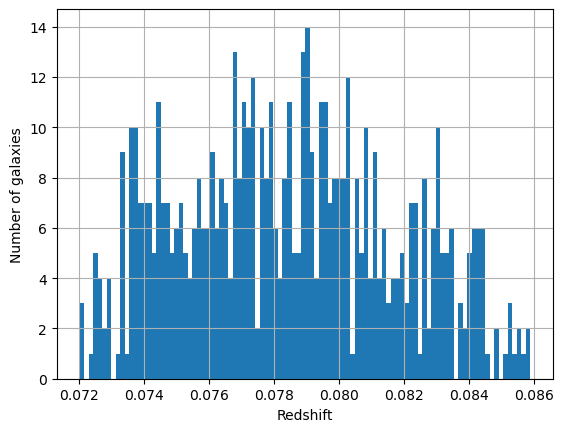

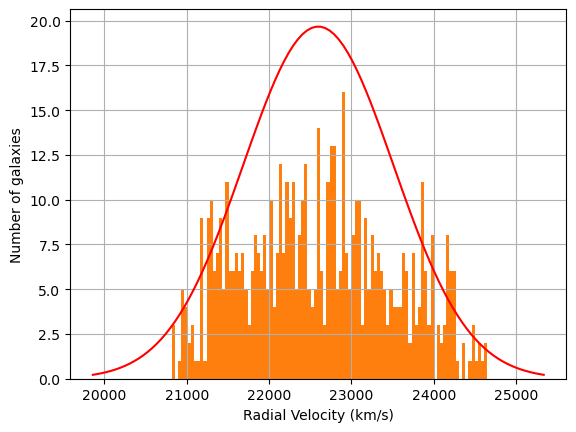

M_200 is 2.546979364952184e+36 km3 kg / m3
1426.2116553225978 arcsec 1502.472841293449 arcsec
R_200 is 1502.472841293449 arcsec
condition -38.13059298542544 arcsec
self consistent False
run number 4
The columns in the data frame are:
 ['main_id' 'ra' 'dec' 'coo_err_maj' 'coo_err_min' 'coo_err_angle'
 'coo_wavelength' 'coo_bibcode' 'rvz_radvel' 'otype' 'rvz_redshift'
 'mesdistance.bibcode' 'mesdistance.dist' 'mesdistance.dist_prec'
 'mesdistance.mespos' 'mesdistance.method' 'mesdistance.minus_err'
 'mesdistance.minus_err_prec' 'mesdistance.plus_err'
 'mesdistance.plus_err_prec' 'mesdistance.qual' 'mesdistance.unit'] 

Selected 2454 galaxies
0       119054.559937
2        11409.332744
3        61266.748718
5        90654.844628
6        23117.941625
            ...      
2682     27333.881843
2684     27521.025530
2685     28024.805859
2686     28051.862158
2687     28230.360399
Name: rvz_radvel, Length: 2454, dtype: float64


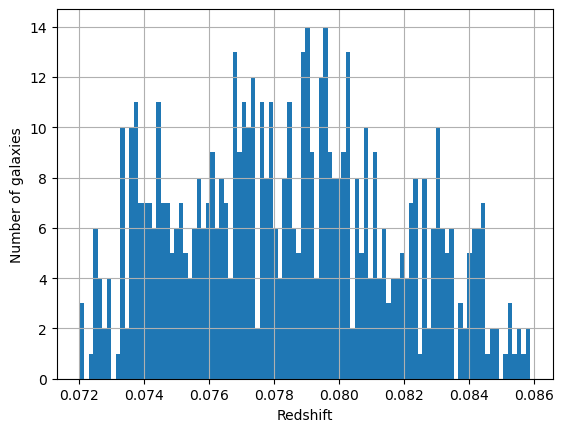

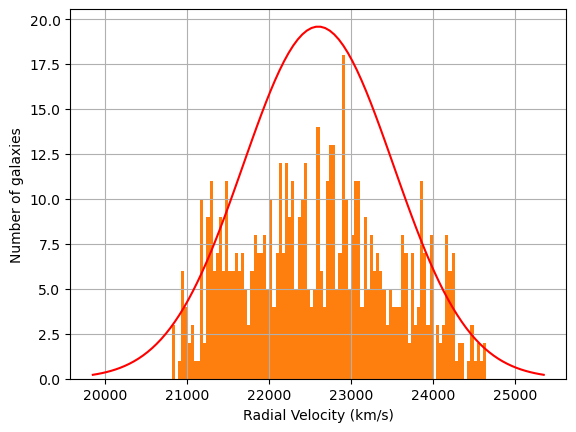

M_200 is 2.5783870348163943e+36 km3 kg / m3
1464.3422483080235 arcsec 1508.6234630914432 arcsec
R_200 is 1508.6234630914432 arcsec
condition -22.140607391709864 arcsec
self consistent False
run number 5
The columns in the data frame are:
 ['main_id' 'ra' 'dec' 'coo_err_maj' 'coo_err_min' 'coo_err_angle'
 'coo_wavelength' 'coo_bibcode' 'rvz_radvel' 'otype' 'rvz_redshift'
 'mesdistance.bibcode' 'mesdistance.dist' 'mesdistance.dist_prec'
 'mesdistance.mespos' 'mesdistance.method' 'mesdistance.minus_err'
 'mesdistance.minus_err_prec' 'mesdistance.plus_err'
 'mesdistance.plus_err_prec' 'mesdistance.qual' 'mesdistance.unit'] 

Selected 2521 galaxies
0       119054.559937
2        11409.332744
3        61266.748718
5        90654.844628
6        23117.941625
            ...      
2752     27333.881843
2754     27521.025530
2755     28024.805859
2756     28051.862158
2757     28230.360399
Name: rvz_radvel, Length: 2521, dtype: float64


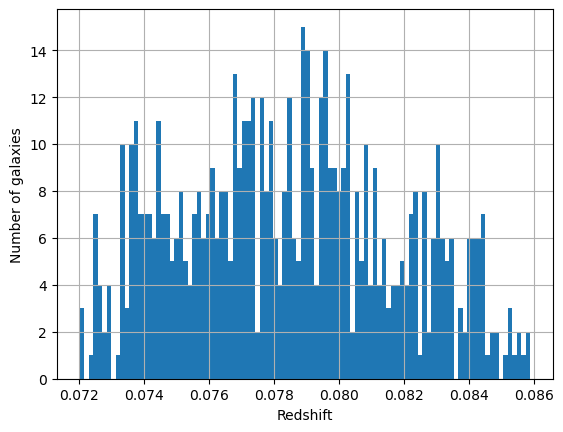

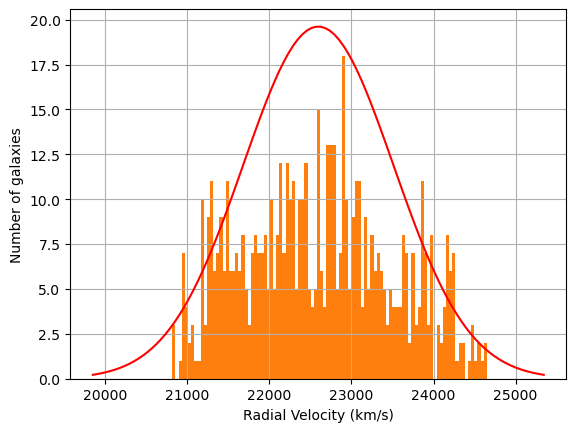

M_200 is 2.5671215270307816e+36 km3 kg / m3
1486.4828556997334 arcsec 1506.4230924006613 arcsec
R_200 is 1506.4230924006613 arcsec
condition -9.970118350463963 arcsec
self consistent False
run number 6
The columns in the data frame are:
 ['main_id' 'ra' 'dec' 'coo_err_maj' 'coo_err_min' 'coo_err_angle'
 'coo_wavelength' 'coo_bibcode' 'rvz_radvel' 'otype' 'rvz_redshift'
 'mesdistance.bibcode' 'mesdistance.dist' 'mesdistance.dist_prec'
 'mesdistance.mespos' 'mesdistance.method' 'mesdistance.minus_err'
 'mesdistance.minus_err_prec' 'mesdistance.plus_err'
 'mesdistance.plus_err_prec' 'mesdistance.qual' 'mesdistance.unit'] 

Selected 2552 galaxies
0       119054.559937
2        11409.332744
3        61266.748718
5        90654.844628
6        23117.941625
            ...      
2783     27333.881843
2785     27521.025530
2786     28024.805859
2787     28051.862158
2788     28230.360399
Name: rvz_radvel, Length: 2552, dtype: float64


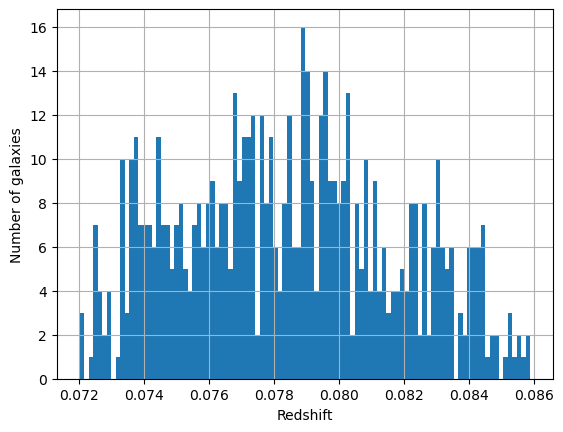

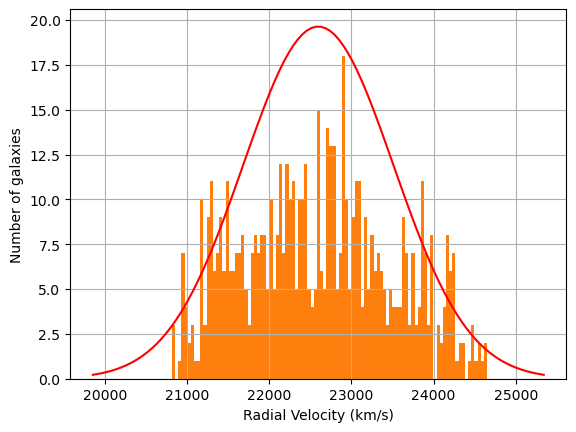

M_200 is 2.5576080012213107e+36 km3 kg / m3
1496.4529740501973 arcsec 1504.5598985489773 arcsec
R_200 is 1504.5598985489773 arcsec
condition -4.0534622493901225 arcsec
self consistent False
run number 7
The columns in the data frame are:
 ['main_id' 'ra' 'dec' 'coo_err_maj' 'coo_err_min' 'coo_err_angle'
 'coo_wavelength' 'coo_bibcode' 'rvz_radvel' 'otype' 'rvz_redshift'
 'mesdistance.bibcode' 'mesdistance.dist' 'mesdistance.dist_prec'
 'mesdistance.mespos' 'mesdistance.method' 'mesdistance.minus_err'
 'mesdistance.minus_err_prec' 'mesdistance.plus_err'
 'mesdistance.plus_err_prec' 'mesdistance.qual' 'mesdistance.unit'] 

Selected 2568 galaxies
0       119054.559937
2        11409.332744
3        61266.748718
5        90654.844628
6        23117.941625
            ...      
2799     27333.881843
2801     27521.025530
2802     28024.805859
2803     28051.862158
2804     28230.360399
Name: rvz_radvel, Length: 2568, dtype: float64


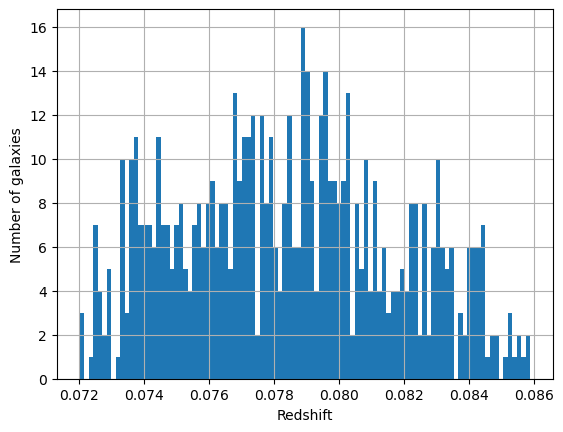

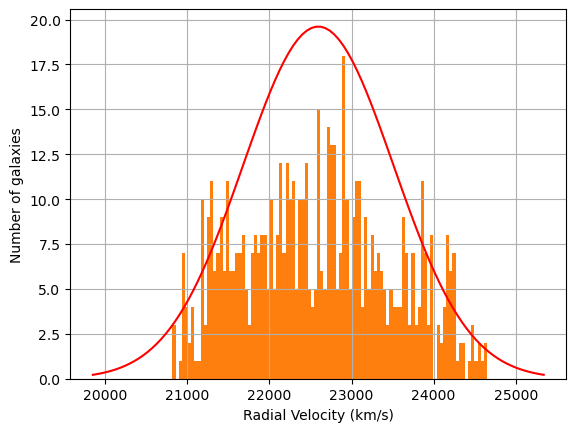

M_200 is 2.5684569540505893e+36 km3 kg / m3
1500.5064362995872 arcsec 1506.6842629173689 arcsec
R_200 is 1506.6842629173689 arcsec
condition -3.088913308890824 arcsec
self consistent False
run number 8
The columns in the data frame are:
 ['main_id' 'ra' 'dec' 'coo_err_maj' 'coo_err_min' 'coo_err_angle'
 'coo_wavelength' 'coo_bibcode' 'rvz_radvel' 'otype' 'rvz_redshift'
 'mesdistance.bibcode' 'mesdistance.dist' 'mesdistance.dist_prec'
 'mesdistance.mespos' 'mesdistance.method' 'mesdistance.minus_err'
 'mesdistance.minus_err_prec' 'mesdistance.plus_err'
 'mesdistance.plus_err_prec' 'mesdistance.qual' 'mesdistance.unit'] 

Selected 2576 galaxies
0       119054.559937
2        11409.332744
3        61266.748718
5        90654.844628
6        23117.941625
            ...      
2809     27333.881843
2811     27521.025530
2812     28024.805859
2813     28051.862158
2814     28230.360399
Name: rvz_radvel, Length: 2576, dtype: float64


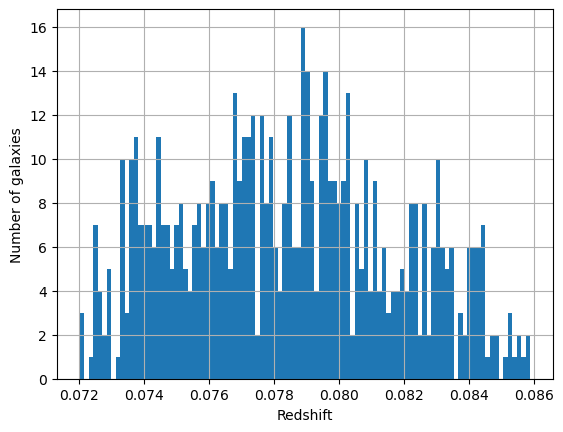

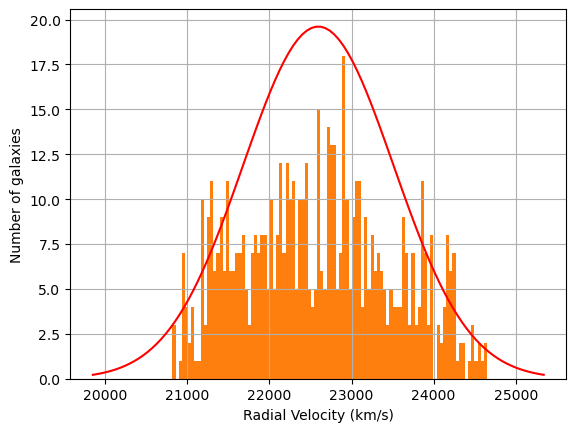

M_200 is 2.5684569540505893e+36 km3 kg / m3
1503.595349608478 arcsec 1506.6842629173689 arcsec
R_200 is 1506.6842629173689 arcsec
condition -1.544456654445412 arcsec
self consistent False
run number 9
The columns in the data frame are:
 ['main_id' 'ra' 'dec' 'coo_err_maj' 'coo_err_min' 'coo_err_angle'
 'coo_wavelength' 'coo_bibcode' 'rvz_radvel' 'otype' 'rvz_redshift'
 'mesdistance.bibcode' 'mesdistance.dist' 'mesdistance.dist_prec'
 'mesdistance.mespos' 'mesdistance.method' 'mesdistance.minus_err'
 'mesdistance.minus_err_prec' 'mesdistance.plus_err'
 'mesdistance.plus_err_prec' 'mesdistance.qual' 'mesdistance.unit'] 

Selected 2579 galaxies
0       119054.559937
2        11409.332744
3        61266.748718
5        90654.844628
6        23117.941625
            ...      
2813     27333.881843
2815     27521.025530
2816     28024.805859
2817     28051.862158
2818     28230.360399
Name: rvz_radvel, Length: 2579, dtype: float64


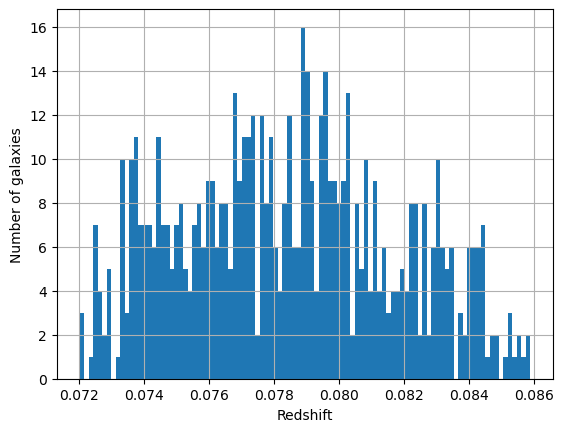

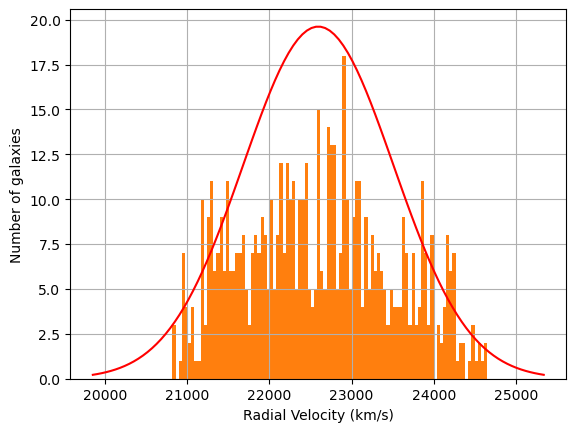

M_200 is 2.565745190578648e+36 km3 kg / m3
1505.1398062629235 arcsec 1506.1538263975585 arcsec
R_200 is 1506.1538263975585 arcsec
condition -0.5070100673174238 arcsec
self consistent False
run number 10
The columns in the data frame are:
 ['main_id' 'ra' 'dec' 'coo_err_maj' 'coo_err_min' 'coo_err_angle'
 'coo_wavelength' 'coo_bibcode' 'rvz_radvel' 'otype' 'rvz_redshift'
 'mesdistance.bibcode' 'mesdistance.dist' 'mesdistance.dist_prec'
 'mesdistance.mespos' 'mesdistance.method' 'mesdistance.minus_err'
 'mesdistance.minus_err_prec' 'mesdistance.plus_err'
 'mesdistance.plus_err_prec' 'mesdistance.qual' 'mesdistance.unit'] 

Selected 2579 galaxies
0       119054.559937
2        11409.332744
3        61266.748718
5        90654.844628
6        23117.941625
            ...      
2813     27333.881843
2815     27521.025530
2816     28024.805859
2817     28051.862158
2818     28230.360399
Name: rvz_radvel, Length: 2579, dtype: float64


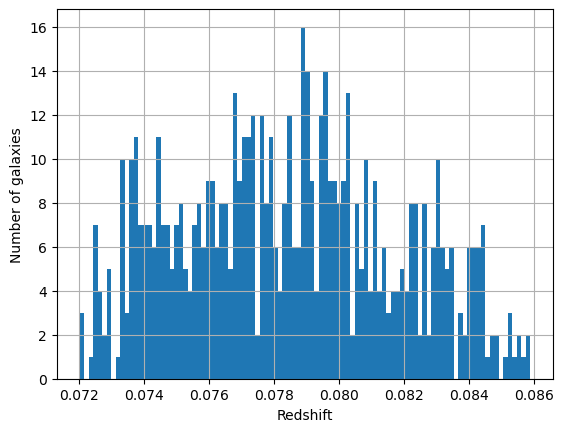

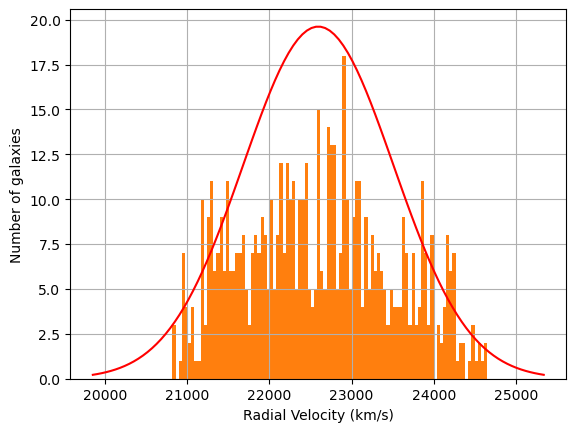

M_200 is 2.565745190578648e+36 km3 kg / m3
1505.646816330241 arcsec 1506.1538263975585 arcsec
R_200 is 1506.1538263975585 arcsec
condition -0.2535050336587119 arcsec
self consistent False
run number 11
The columns in the data frame are:
 ['main_id' 'ra' 'dec' 'coo_err_maj' 'coo_err_min' 'coo_err_angle'
 'coo_wavelength' 'coo_bibcode' 'rvz_radvel' 'otype' 'rvz_redshift'
 'mesdistance.bibcode' 'mesdistance.dist' 'mesdistance.dist_prec'
 'mesdistance.mespos' 'mesdistance.method' 'mesdistance.minus_err'
 'mesdistance.minus_err_prec' 'mesdistance.plus_err'
 'mesdistance.plus_err_prec' 'mesdistance.qual' 'mesdistance.unit'] 

Selected 2579 galaxies
0       119054.559937
2        11409.332744
3        61266.748718
5        90654.844628
6        23117.941625
            ...      
2813     27333.881843
2815     27521.025530
2816     28024.805859
2817     28051.862158
2818     28230.360399
Name: rvz_radvel, Length: 2579, dtype: float64


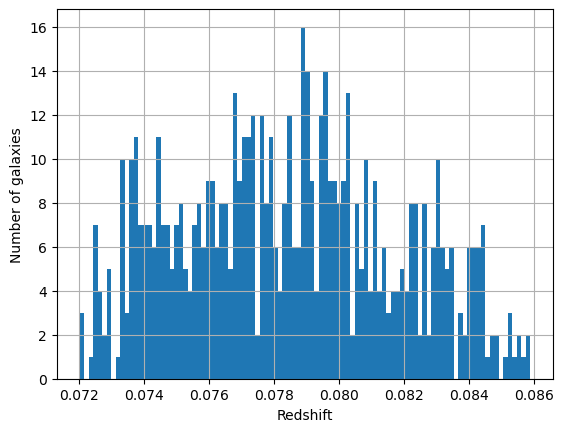

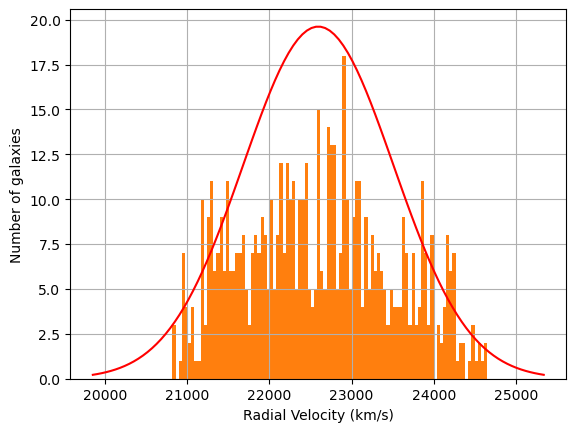

M_200 is 2.565745190578648e+36 km3 kg / m3
1505.9003213638998 arcsec 1506.1538263975585 arcsec
R_200 is 1506.1538263975585 arcsec
condition -0.12675251682935595 arcsec
self consistent False
run number 12
The columns in the data frame are:
 ['main_id' 'ra' 'dec' 'coo_err_maj' 'coo_err_min' 'coo_err_angle'
 'coo_wavelength' 'coo_bibcode' 'rvz_radvel' 'otype' 'rvz_redshift'
 'mesdistance.bibcode' 'mesdistance.dist' 'mesdistance.dist_prec'
 'mesdistance.mespos' 'mesdistance.method' 'mesdistance.minus_err'
 'mesdistance.minus_err_prec' 'mesdistance.plus_err'
 'mesdistance.plus_err_prec' 'mesdistance.qual' 'mesdistance.unit'] 

Selected 2579 galaxies
0       119054.559937
2        11409.332744
3        61266.748718
5        90654.844628
6        23117.941625
            ...      
2813     27333.881843
2815     27521.025530
2816     28024.805859
2817     28051.862158
2818     28230.360399
Name: rvz_radvel, Length: 2579, dtype: float64


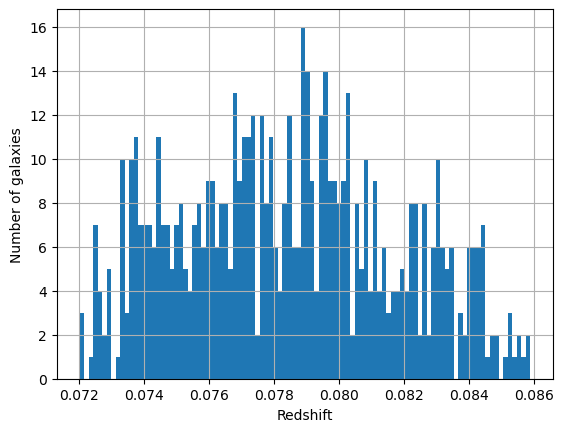

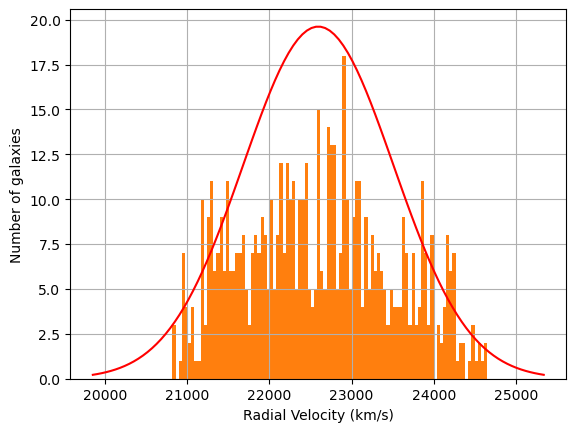

M_200 is 2.565745190578648e+36 km3 kg / m3
1506.0270738807292 arcsec 1506.1538263975585 arcsec
R_200 is 1506.1538263975585 arcsec
condition -0.06337625841479166 arcsec
self consistent False
run number 13
The columns in the data frame are:
 ['main_id' 'ra' 'dec' 'coo_err_maj' 'coo_err_min' 'coo_err_angle'
 'coo_wavelength' 'coo_bibcode' 'rvz_radvel' 'otype' 'rvz_redshift'
 'mesdistance.bibcode' 'mesdistance.dist' 'mesdistance.dist_prec'
 'mesdistance.mespos' 'mesdistance.method' 'mesdistance.minus_err'
 'mesdistance.minus_err_prec' 'mesdistance.plus_err'
 'mesdistance.plus_err_prec' 'mesdistance.qual' 'mesdistance.unit'] 

Selected 2579 galaxies
0       119054.559937
2        11409.332744
3        61266.748718
5        90654.844628
6        23117.941625
            ...      
2813     27333.881843
2815     27521.025530
2816     28024.805859
2817     28051.862158
2818     28230.360399
Name: rvz_radvel, Length: 2579, dtype: float64


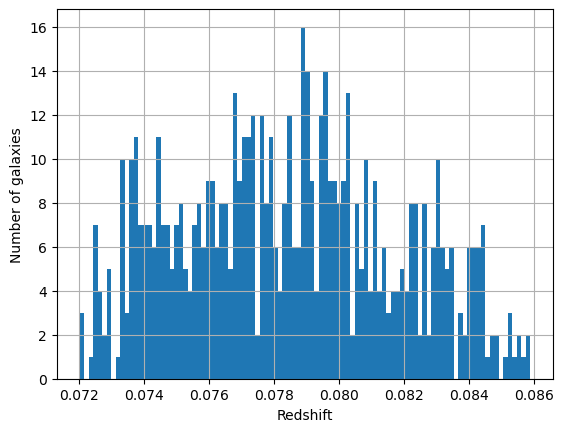

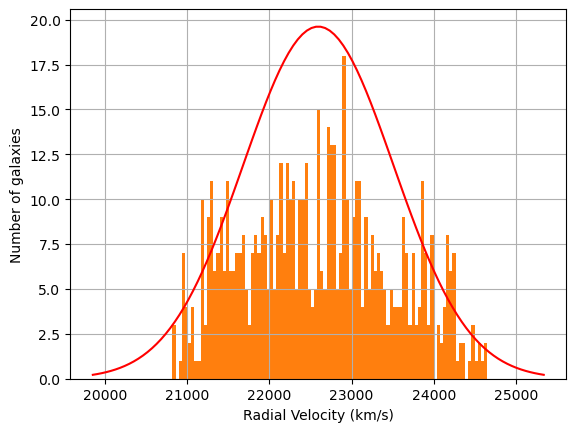

M_200 is 2.565745190578648e+36 km3 kg / m3
1506.0904501391437 arcsec 1506.1538263975585 arcsec
R_200 is 1506.1538263975585 arcsec
condition -0.03168812920739583 arcsec
self consistent False
run number 14
The columns in the data frame are:
 ['main_id' 'ra' 'dec' 'coo_err_maj' 'coo_err_min' 'coo_err_angle'
 'coo_wavelength' 'coo_bibcode' 'rvz_radvel' 'otype' 'rvz_redshift'
 'mesdistance.bibcode' 'mesdistance.dist' 'mesdistance.dist_prec'
 'mesdistance.mespos' 'mesdistance.method' 'mesdistance.minus_err'
 'mesdistance.minus_err_prec' 'mesdistance.plus_err'
 'mesdistance.plus_err_prec' 'mesdistance.qual' 'mesdistance.unit'] 

Selected 2579 galaxies
0       119054.559937
2        11409.332744
3        61266.748718
5        90654.844628
6        23117.941625
            ...      
2813     27333.881843
2815     27521.025530
2816     28024.805859
2817     28051.862158
2818     28230.360399
Name: rvz_radvel, Length: 2579, dtype: float64


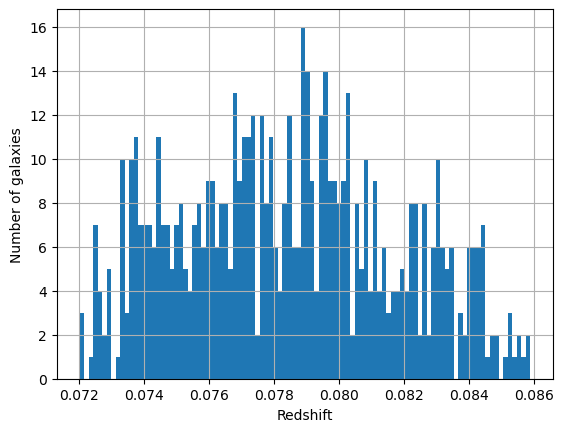

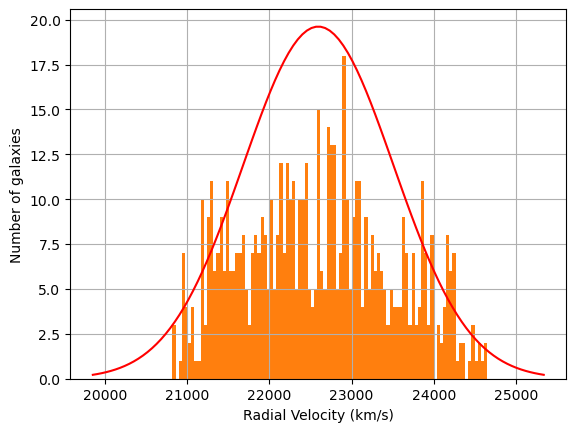

M_200 is 2.565745190578648e+36 km3 kg / m3
1506.1221382683511 arcsec 1506.1538263975585 arcsec
R_200 is 1506.1538263975585 arcsec
condition -0.015844064603697916 arcsec
self consistent False
run number 15
The columns in the data frame are:
 ['main_id' 'ra' 'dec' 'coo_err_maj' 'coo_err_min' 'coo_err_angle'
 'coo_wavelength' 'coo_bibcode' 'rvz_radvel' 'otype' 'rvz_redshift'
 'mesdistance.bibcode' 'mesdistance.dist' 'mesdistance.dist_prec'
 'mesdistance.mespos' 'mesdistance.method' 'mesdistance.minus_err'
 'mesdistance.minus_err_prec' 'mesdistance.plus_err'
 'mesdistance.plus_err_prec' 'mesdistance.qual' 'mesdistance.unit'] 

Selected 2579 galaxies
0       119054.559937
2        11409.332744
3        61266.748718
5        90654.844628
6        23117.941625
            ...      
2813     27333.881843
2815     27521.025530
2816     28024.805859
2817     28051.862158
2818     28230.360399
Name: rvz_radvel, Length: 2579, dtype: float64


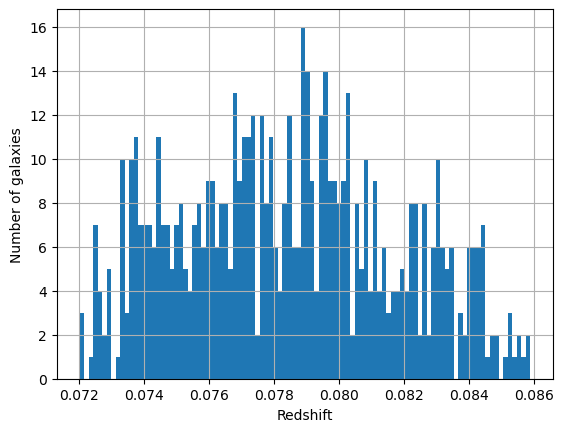

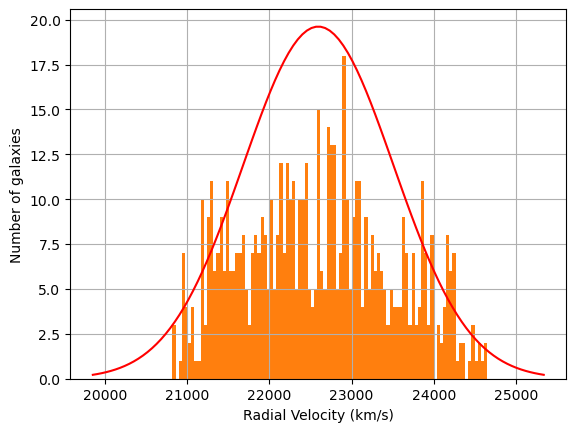

M_200 is 2.565745190578648e+36 km3 kg / m3
1506.1379823329548 arcsec 1506.1538263975585 arcsec
R_200 is 1506.1538263975585 arcsec
condition -0.007922032301848958 arcsec
self consistent False
run number 16
The columns in the data frame are:
 ['main_id' 'ra' 'dec' 'coo_err_maj' 'coo_err_min' 'coo_err_angle'
 'coo_wavelength' 'coo_bibcode' 'rvz_radvel' 'otype' 'rvz_redshift'
 'mesdistance.bibcode' 'mesdistance.dist' 'mesdistance.dist_prec'
 'mesdistance.mespos' 'mesdistance.method' 'mesdistance.minus_err'
 'mesdistance.minus_err_prec' 'mesdistance.plus_err'
 'mesdistance.plus_err_prec' 'mesdistance.qual' 'mesdistance.unit'] 

Selected 2579 galaxies
0       119054.559937
2        11409.332744
3        61266.748718
5        90654.844628
6        23117.941625
            ...      
2813     27333.881843
2815     27521.025530
2816     28024.805859
2817     28051.862158
2818     28230.360399
Name: rvz_radvel, Length: 2579, dtype: float64


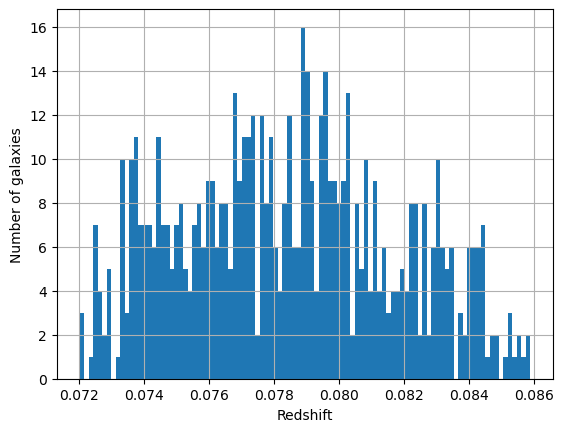

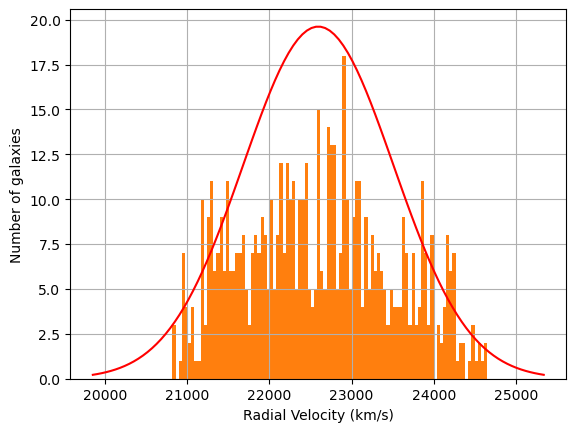

M_200 is 2.565745190578648e+36 km3 kg / m3
1506.1459043652567 arcsec 1506.1538263975585 arcsec
R_200 is 1506.1538263975585 arcsec
condition -0.003961016150924479 arcsec
self consistent False
run number 17
The columns in the data frame are:
 ['main_id' 'ra' 'dec' 'coo_err_maj' 'coo_err_min' 'coo_err_angle'
 'coo_wavelength' 'coo_bibcode' 'rvz_radvel' 'otype' 'rvz_redshift'
 'mesdistance.bibcode' 'mesdistance.dist' 'mesdistance.dist_prec'
 'mesdistance.mespos' 'mesdistance.method' 'mesdistance.minus_err'
 'mesdistance.minus_err_prec' 'mesdistance.plus_err'
 'mesdistance.plus_err_prec' 'mesdistance.qual' 'mesdistance.unit'] 

Selected 2579 galaxies
0       119054.559937
2        11409.332744
3        61266.748718
5        90654.844628
6        23117.941625
            ...      
2813     27333.881843
2815     27521.025530
2816     28024.805859
2817     28051.862158
2818     28230.360399
Name: rvz_radvel, Length: 2579, dtype: float64


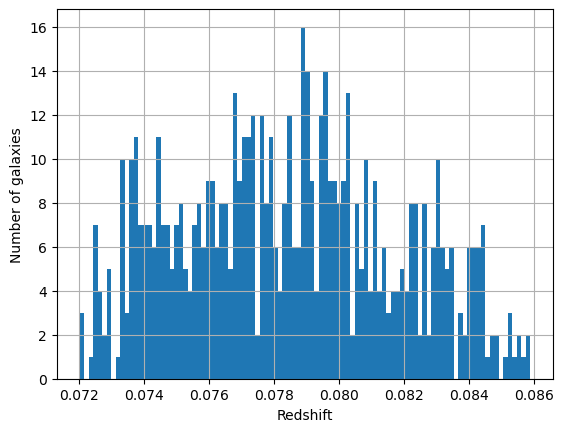

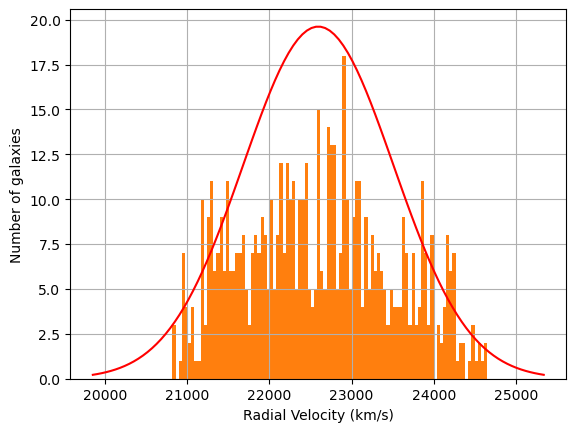

M_200 is 2.565745190578648e+36 km3 kg / m3
1506.1498653814076 arcsec 1506.1538263975585 arcsec
R_200 is 1506.1538263975585 arcsec
condition -0.0019805080755759263 arcsec
self consistent False
run number 18
The columns in the data frame are:
 ['main_id' 'ra' 'dec' 'coo_err_maj' 'coo_err_min' 'coo_err_angle'
 'coo_wavelength' 'coo_bibcode' 'rvz_radvel' 'otype' 'rvz_redshift'
 'mesdistance.bibcode' 'mesdistance.dist' 'mesdistance.dist_prec'
 'mesdistance.mespos' 'mesdistance.method' 'mesdistance.minus_err'
 'mesdistance.minus_err_prec' 'mesdistance.plus_err'
 'mesdistance.plus_err_prec' 'mesdistance.qual' 'mesdistance.unit'] 

Selected 2579 galaxies
0       119054.559937
2        11409.332744
3        61266.748718
5        90654.844628
6        23117.941625
            ...      
2813     27333.881843
2815     27521.025530
2816     28024.805859
2817     28051.862158
2818     28230.360399
Name: rvz_radvel, Length: 2579, dtype: float64


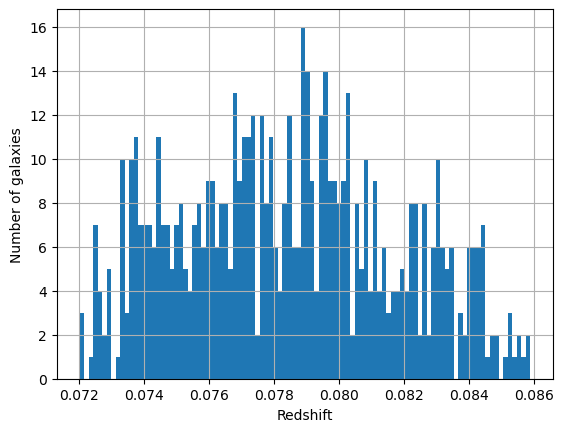

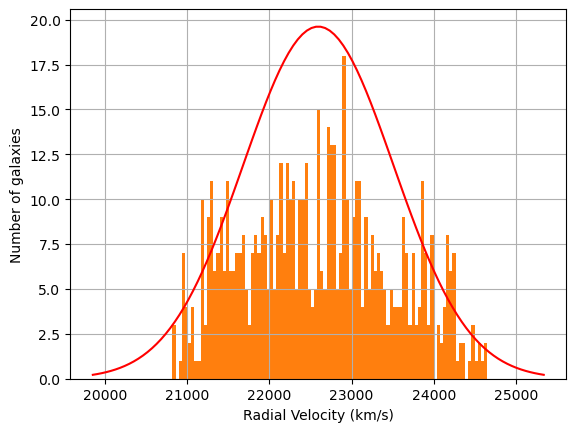

M_200 is 2.565745190578648e+36 km3 kg / m3
1506.151845889483 arcsec 1506.1538263975585 arcsec
R_200 is 1506.1538263975585 arcsec
condition -0.0009902540377879632 arcsec
self consistent True
self consistent value found
R_200= 25.102563773292644 arcmin
M_200= 1.2903502584594986 solMass x10^15
Values for M 200
Eckert et al: 1.225 solMass x10^15 Our calculations: 1.2903502584594986 solMass x10^15
Values for gas fraction
Eckert et al: 0.152 Our calculations: 0.14430190467997217
Matter density is: 0.2905175559135573


In [37]:
# set up libraries
import numpy as np
import matplotlib.pyplot as plt
from astroquery.simbad import Simbad
import astropy.coordinates as coord
import pandas
import scipy
import astropy.constants as cons
import scipy.constants as math_cons
from astropy.cosmology import WMAP9 as cosmo
from astropy import units as u
import astropy.cosmology.units as cu
# set up custom query and define which columns we want
customSimbad = Simbad()
customSimbad.add_votable_fields('ra', 'dec', 'mesdistance', 'otype','rvz_radvel', 'rvz_redshift')
#customSimbad.remove_votable_fields('coordinates')
# set RA, Dec and search radius
my_ra = 227.773
my_dec = 5.744
# use 0.25 degrees as an example
my_radius = '0d20m0s'
guessed_radius = float(my_radius[0])*3600 +float(my_radius[2:4])*60 + float(my_radius[:1])
guessed_radius = guessed_radius*(u.arcsec)
R_200 = guessed_radius
R_200_arcsec = R_200
iteration = 0
self_consistent = False

while not self_consistent:
    iteration = iteration + 1
    print('run number', iteration)
    # run query
    result_table = customSimbad.query_region(coord.SkyCoord(my_ra,my_dec, unit='deg'),radius=guessed_radius)
    # convert output to pandas data frame
    df = result_table.to_pandas()

    print("The columns in the data frame are:\n",df.columns.values,"\n")
    gal_df=df[df['otype']=='G']
    print('Selected',len(gal_df),'galaxies')
    print(gal_df['rvz_radvel'])


    galaxy_cluster = gal_df[(gal_df['rvz_redshift'] <0.086 )& (gal_df['rvz_redshift'] >0.072)]
    galaxy_cluster['rvz_redshift'].hist(bins=100)
    plt.xlabel('Redshift')
    plt.ylabel('Number of galaxies')
    plt.show()
    galaxy_cluster['rvz_radvel'].hist(bins=100)
    plt.xlabel('Radial Velocity (km/s)')
    plt.ylabel('Number of galaxies')
    plt.show

    standardised_plot = galaxy_cluster['rvz_radvel']
    standardised_plot.hist(bins=100)
    import scipy.stats as stats
    mean =galaxy_cluster['rvz_radvel'].mean()
    standarddev= galaxy_cluster['rvz_radvel'].std()#*np.sqrt(3)
    x = np.linspace(mean - 3*standarddev, mean + 3*standarddev, 100)
    norm_factor = np.sqrt(2*math_cons.pi*standarddev**2)
    plt.plot(x, stats.norm.pdf(x, mean, standarddev)*45000,'r')
    plt.show()

    redshift = 0.0766
    rho_200 = 200*cosmo.critical_density(redshift).to(u.kg/u.m**3)
    standarddev_SI = standarddev*(u.km/u.s)
    M_200 = np.sqrt(((27)/(cons.G**3))*(standarddev_SI**6)*((3)/(4*math_cons.pi*rho_200)))
    
    print('M_200 is',M_200)
    R_200 = (3*M_200/(4*math_cons.pi*rho_200))**(1/3)
    angular_diameter = cosmo.angular_diameter_distance(redshift)
    R_200_arcsec = (R_200/ angular_diameter).to(u.arcsec, equivalencies=u.dimensionless_angles())
    
    print(guessed_radius, R_200_arcsec)
    guessed_radius = (guessed_radius+R_200_arcsec)/2

    print('R_200 is',R_200_arcsec)
    if np.sqrt(((guessed_radius - R_200_arcsec)/(u.arcsec))**2 ) <=0.001:
        self_consistent = True
    print('condition', guessed_radius-R_200_arcsec)
    print('self consistent', self_consistent)

print('self consistent value found')

R_200_kpc = R_200.to(u.kpc)/cosmo.kpc_proper_per_arcmin(redshift)
print('R_200=',R_200_kpc)
M_200 = M_200.to(u.solMass)
print('M_200=',M_200/10**15,'x10^15')
#eckert M 200 data
eckert_M_HSE = 12.25*10**14*(u.solMass)
eckert_M_HSE_uncertainty = 0.49*10**14*(u.solMass)
eckert_f_gas = 0.152
eckert_f_gas_uncertainty = 0.006

M_gas_eckert = eckert_f_gas * eckert_M_HSE
M_gas_eckert_uncertainty = np.sqrt((eckert_M_HSE**2)*(eckert_f_gas_uncertainty**2)+(eckert_f_gas**2)*(eckert_M_HSE_uncertainty**2))

#our M 200 data
f_gas = M_gas_eckert / M_200

print('Values for M 200')
print('Eckert et al:',eckert_M_HSE/(10**15),'x10^15','Our calculations:',M_200/(10**15),'x10^15')

print('Values for gas fraction')
print('Eckert et al:',eckert_f_gas,'Our calculations:',f_gas)

#finding omega M
f_star = 0.015
f_star_uncertainty=0.005
f_b = f_star + f_gas

omega_b = 0.04628
omega_b_uncertainty = 0.00093
omega_M = omega_b/f_b
print('Matter density is:',omega_M)

In [38]:
bootstrap_loops = 5000
velocity_bootstraps = np.zeros(bootstrap_loops)

for i in range (bootstrap_loops):
    # get the number of velocities in the array
    N = len(galaxy_cluster['rvz_radvel'])
    # sample the same number of velocities from the original array with replacement
    v_array_sample = np.random.choice(galaxy_cluster['rvz_radvel'],N,replace=True)
    velocity_bootstraps[i] = v_array_sample.std()

standarddev_error = velocity_bootstraps.std()
print('the line of sight velocity dispersion error is',standarddev_error,'km/s')

the line of sight velocity dispersion error is 19.804063548532937 km/s


In [39]:
print(standarddev)

915.0595799266056


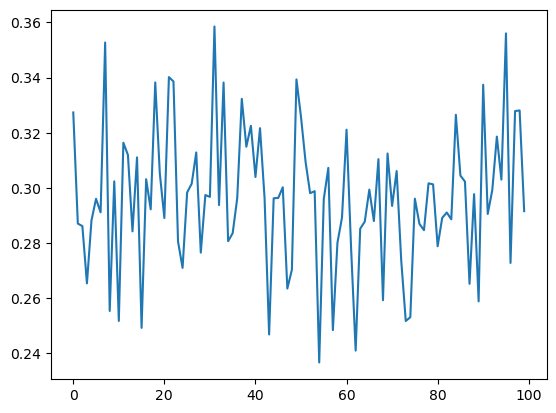

Omega M = 0.2905175559135573 +- 0.025518565059202258


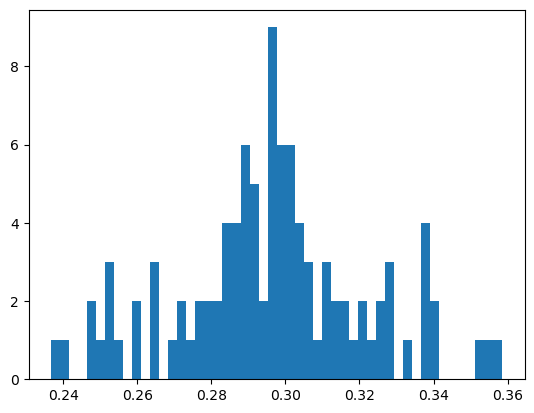

In [53]:
monte_carlo_runs = 100
omega_lambda_range = np.random.normal(loc=0.7135,scale=0.0096,size=monte_carlo_runs)
omega_m_range = np.random.normal(loc=0.2865,scale=0.0088,size=monte_carlo_runs)
h_nought_range = np.random.normal(loc=69.32,scale=0.08,size=monte_carlo_runs)
standarddev_range = np.random.normal(loc=standarddev,scale=standarddev_error,size=monte_carlo_runs)
f_gas_eckert_range = np.random.normal(loc=eckert_f_gas,scale=eckert_f_gas_uncertainty,size=monte_carlo_runs)
m_hse_eckert_range = np.random.normal(loc=eckert_M_HSE/(u.solMass),scale=eckert_M_HSE_uncertainty/(u.solMass)
                                      ,size=monte_carlo_runs)
f_star_range = np.random.normal(loc=f_star,scale=f_star_uncertainty,size=monte_carlo_runs)
omega_b_range = np.random.normal(loc=omega_b,scale=omega_b_uncertainty,size=monte_carlo_runs)

#plotted to see any unphysical values
#plt.plot(omega_lambda_range)
#plt.show()
#plt.plot(omega_m_range)
#plt.show()
#plt.plot(h_nought_range)
#plt.show()
#plt.plot(standarddev_range)
#plt.show()
#plt.plot(f_gas_eckert_range)
#plt.show()
#plt.plot(m_hse_eckert_range)
#plt.show()
#plt.plot(f_star_range)
#plt.show()
#plt.plot(omega_b_range)
#plt.show()

##calculations
omega_m_mc_results = np.zeros(monte_carlo_runs)
for i in range (monte_carlo_runs):
    omega_lambda_rand = omega_lambda_range[i]
    omega_m_rand = omega_m_range[i]
    h_nought_rand = h_nought_range[i] * (u.km/(u.s*u.Mpc))
    standarddev_rand = standarddev_range[i] * (u.km/u.s)
    f_gas_eckert_rand = f_gas_eckert_range[i]
    m_hse_eckert_rand = m_hse_eckert_range[i] * (u.solMass)
    f_star_rand = f_star_range[i]
    omega_b_rand = omega_b_range[i]
    
    rho_200_rand = 200*(3*(h_nought_rand**2)*(omega_m_rand*((1+redshift)**3)+omega_lambda_rand))/(8*math_cons.pi*cons.G)
    rho_200_rand = rho_200_rand.to(u.kg/u.m**3)
    
    M_200_rand = np.sqrt(((27)/(cons.G**3))*(standarddev_rand**6)*((3)/(4*math_cons.pi*rho_200_rand))

    M_gas_eckert_rand = f_gas_eckert_rand * m_hse_eckert_rand

    f_gas_rand = M_gas_eckert_rand / M_200_rand
    
    f_b_rand = f_star_rand + f_gas_rand
    omega_m_mc_results[i] = omega_b_rand/f_b_rand
plt.plot(omega_m_mc_results)
plt.show()
plt.hist(omega_m_mc_results,bins=50)
print('Omega M =',omega_M,'+-',omega_m_mc_results.std())